# Analyse complète du corpus de 1964

Ce notebook rassemble les quatre TP sur le même corpus, les journaux de 1964 :

1. **Mots-clés** avec YAKE
2. **Nuage de mots**, après enrichissement de la liste de stopwords
3. **Entités nommées** avec spaCy : personnes, organisations, lieux
4. **Analyse de sentiment** de 10 phrases, avec TextBlob-FR puis avec un modèle transformers

Les imports et la configuration sont en haut. Chaque partie commence par une explication courte.

## Installation (à lancer une seule fois)

In [1]:
!uv pip install sentencepiece
!uv pip install "transformers>=5.19.0"

Using Python 3.13.9 environment at: /home/minasema/tac/.venv
Checked 1 package in 2ms
Using Python 3.13.9 environment at: /home/minasema/tac/.venv
Checked 1 package in 2ms


## Imports

In [ ]:
import os
import re
import random
from collections import Counter

import pandas as pd
import nltk
import yake
import spacy
from nltk.corpus import stopwords
from wordcloud import WordCloud
from IPython.display import Image
from textblob import Blobber 
from textblob_fr import PatternTagger, PatternAnalyzer
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

nltk.download("stopwords")

/home/minasema/tac/.venv/lib/python3.13/site-packages/torch/cuda/__init__.py:1174: UserWarning: Can't initialize NVML
  raw_cnt = _raw_device_count_nvml()
/home/minasema/tac/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[nltk_data] Downloading package stopwords to
[nltk_data]     /home/minasema/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

## Configuration et chargement des outils

- `txt_path` : dossier des journaux (le notebook est dans `tps/tp2`, donc on remonte de deux niveaux).
- `year` : l'année étudiée.
- `SEUIL` : un mot, une personne, une organisation ou un lieu ne sont retenus que s'ils apparaissent dans au moins 5 journaux.

In [3]:
txt_path = "../../data/txt"
temp_path = "../../data/tmp"
year = 1964
SEUIL = 5

os.makedirs(temp_path, exist_ok=True)

txts = [f for f in sorted(os.listdir(txt_path)) if str(year) in f]
print(len(txts), "journaux de", year)

100 journaux de 1964


In [4]:
nlp = spacy.load("fr_core_news_md")
tb = Blobber(pos_tagger=PatternTagger(), analyzer=PatternAnalyzer())

tokenizer = AutoTokenizer.from_pretrained("philschmid/pt-tblard-tf-allocine")
model = AutoModelForSequenceClassification.from_pretrained("philschmid/pt-tblard-tf-allocine")
sentiment_analyser = pipeline("sentiment-analysis", model=model, tokenizer=tokenizer)

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 45313.36it/s]


---

## Partie 1 : mots-clés avec YAKE

YAKE repère les expressions les plus caractéristiques d'un texte. On ne garde ici que les expressions de deux mots (bigrammes), plus lisibles qu'un mot isolé.

In [5]:
kw_extractor = yake.KeywordExtractor(lan="fr", top=50)

for f in txts[:5]:
    with open(os.path.join(txt_path, f), encoding="utf-8") as fh:
        keywords = kw_extractor.extract_keywords(fh.read())
    bigrammes = [kw for kw, score in keywords if len(kw.split()) == 2]
    print(f"{f} : {', '.join(bigrammes)}")

KB_JB838_1964-01-04_01-00025.txt : OPel Rek, Prix variant, drap Uni, OPEL Kap, l'essuie DRAPS, bon état, nappe ESSUIE, ESSUIE EPONGE, HOME Tél, part état, part Mercédè
KB_JB838_1964-01-18_01-00008.txt : THEATRE NATIONAL, Camille Roussel, BOURSE BELGE, CENTRE ROGIER, THEATRE FLAMAND, Richard III, janvier OPERA, Théâtre National, Ancienne Belgique, Jaffa vient, OPERA NATIONAL, Delta Rythm, rue Royale
KB_JB838_1964-01-18_01-00018.txt : Agence Rossel, L’AGENCE ROSSEL, SHOE L'INDEX, PRESSE ANNONCE, EXEMPLES Chaussures, SOIR SAMEDI, Ecrire Agence, Véritables bottes, employée dactylo
KB_JB838_1964-01-29_01-00015.txt : jolie villa, Agence Rossel, Belle VILLA, bon état, MAISON ouvrière, bonne MAISON, maison Tél
KB_JB838_1964-01-29_01-00017.txt : Agence Rossel, Rossel num, l’Agence Rossel, faire offre, curriculum vitae, service militaire, Ecrire Agence, entrée immédiate, libre service


---

## Partie 2 : nuage de mots

### Étape 1 : compter dans combien de journaux apparaît chaque mot

Chaque mot compte une seule fois par journal, même s'il apparaît plusieurs fois dans le même journal.

Stopwords : la liste française de NLTK, complétée par nos propres ajouts.

In [6]:
sw = set(stopwords.words("french"))
sw.update([
    "les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
    "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
    "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
    "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
    "van", "het", "autre", "jusqu", "ville", "rossel", "dem",
])

presence = Counter()
for f in txts:
    with open(os.path.join(txt_path, f), encoding="utf-8") as fh:
        mots = set(
            w.upper() for w in nltk.wordpunct_tokenize(fh.read())
            if len(w) > 2 and w.isalpha() and w.lower() not in sw
        )
    presence.update(mots)

print(len(presence), "mots différents")
for i, (mot, n) in enumerate(presence.most_common(30), start=1):
    print(f"{i:2}. {mot} : {n} journaux")

57063 mots différents
 1. BRUXELLES : 98 journaux
 2. SOIR : 95 journaux
 3. TRÈS : 94 journaux
 4. HEURES : 91 journaux
 5. ANS : 91 journaux
 6. GRAND : 90 journaux
 7. JOURS : 88 journaux
 8. PLACE : 86 journaux
 9. TOUTE : 84 journaux
10. RUE : 84 journaux
11. PRIX : 84 journaux
12. BON : 83 journaux
13. PEU : 83 journaux
14. PART : 82 journaux
15. AVANT : 82 journaux
16. QUELQUES : 81 journaux
17. MOIS : 80 journaux
18. ETC : 79 journaux
19. SAMEDI : 78 journaux
20. BELGIQUE : 78 journaux
21. FIN : 76 journaux
22. TEMPS : 76 journaux
23. FRANCE : 75 journaux
24. MIDI : 75 journaux
25. COURS : 74 journaux
26. JOUR : 74 journaux
27. SERVICE : 73 journaux
28. SAINT : 73 journaux
29. GRANDE : 72 journaux
30. PARTIE : 72 journaux


### Étape 2 : retirer les mots inutiles

On retire les mots qui ne disent rien du contenu de l'année, en gardant une raison pour chacun :

| Mot | Raison |
|---|---|
| BRUXELLES | Ville du journal : présente partout, ne caractérise pas l'année |
| SOIR | Nom du journal lui-même |
| TRÈS, PEU, QUELQUES, TOUTE, PAR, AVANT | Mots grammaticaux ou d'intensité |
| HEURES, ANS, JOURS, SAMEDI | Mots de temps, sans contenu propre |
| GRAND, PLACE, RUE | Mots génériques (adresses, adjectifs) |

On ne garde aussi que les mots d'au moins 4 lettres et présents dans au moins `SEUIL` journaux.

In [7]:
retires = [
    "BRUXELLES", "SOIR", "TRÈS", "HEURES", "ANS", "GRAND", "JOURS", "PLACE",
    "RUE", "TOUTE", "PEU", "AVANT", "PAR", "QUELQUES", "SAMEDI",
]

utiles = {
    mot: n for mot, n in presence.items()
    if len(mot) >= 4 and n >= SEUIL and mot not in retires
}
print(len(utiles), "mots gardés pour le nuage")

6950 mots gardés pour le nuage


### Étape 3 : générer le nuage de mots

La taille d'un mot dans le nuage dépend du nombre de journaux où il apparaît.

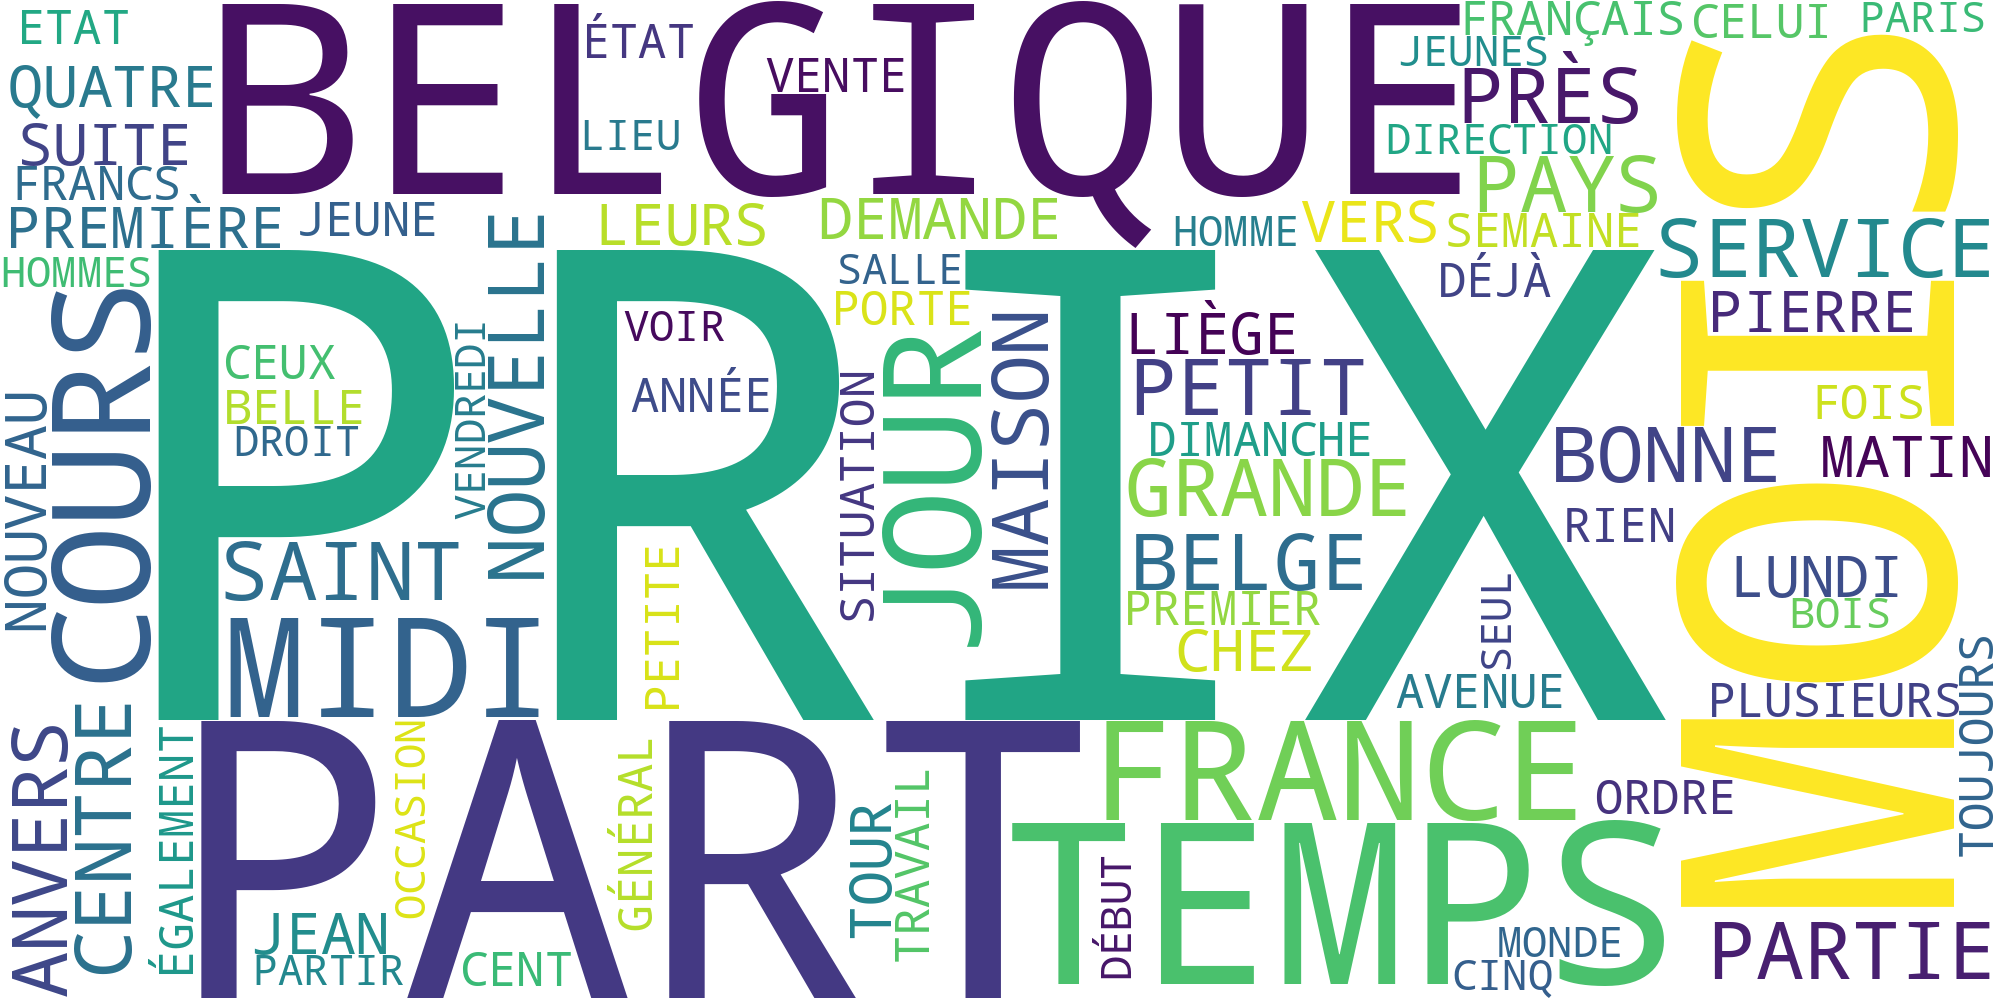

In [8]:
cloud = WordCloud(
    width=2000, height=1000, background_color="white", max_words=80
).generate_from_frequencies(utiles)

cloud.to_file(os.path.join(temp_path, f"{year}_etape3.png"))
Image(filename=os.path.join(temp_path, f"{year}_etape3.png"))

### Étape 4 : conclusion sur le nuage

Le mot le plus gros est **PRIX**, suivi de **PART**, **TEMPS**, **BELGIQUE** et **JOUR**. Les mots les plus présents tournent autour de trois idées :

- **L'économie et les annonces** : PRIX, VENTE, COURS, DEMANDE, SERVICE, PART. Un journal de 1964 contient beaucoup d'annonces et de cours, ce qui explique ces mots très fréquents.
- **La Belgique et ses villes** : BELGIQUE, BELGE, LIÈGE, ANVERS, PARIS, FRANCE, FRANÇAIS, PAYS. Le journal est centré sur la Belgique, avec une forte présence de la France.
- **Le temps et les jours** : TEMPS, JOUR, MIDI, MATIN, LUNDI, DIMANCHE, VENDREDI, SEMAINE. Ce sont des repères de l'agenda quotidien (programmes, horaires, rendez-vous).

Le nuage ne dit pas l'événement marquant de l'année : il montre les mots qui reviennent le plus souvent dans les journaux. Il reflète donc surtout la vie quotidienne et les annonces, plus que les grands sujets.

Limites : certains mots sont des fragments d'OCR (CENT, PARTIR, ETAT) ou sont ambigus (COURS peut être une cote boursière ou un cours de formation ; TEMPS peut être la météo ou la durée). Le nuage n'est lisible qu'après le retrait des mots inutiles de l'étape 2, et son résultat dépend de ce choix.

---

## Partie 3 : entités nommées avec spaCy

spaCy repère dans le texte les personnes (PER), les organisations (ORG) et les lieux (LOC). Comme pour les mots, une entité compte une seule fois par journal. On écarte les fragments de moins de 4 lettres, les abréviations avec un point, et les entrées de la liste d'exclusion de chaque type.

### Test du modèle

In [9]:
test = nlp("Pierre Harmel est arrivé à Bruxelles pour le gouvernement belge.")
for ent in test.ents:
    print(ent.text, ent.label_)

Pierre Harmel PER
Bruxelles LOC


### Listes d'exclusion

Les personnes et les organisations sont à compléter avec les listes que vous avez établies dans votre notebook d'entités nommées (étapes 2 et 3). Les lieux sont établis d'après les 200 premiers lieux bruts.

In [10]:
# TODO : coller ici la liste d'exclusion de l'étape 2 (personnes) de votre notebook
exclus_per = set()

# TODO : coller ici la liste d'exclusion de l'étape 3 (organisations) de votre notebook
exclus_org = set()

exclus_loc = {
    "BRUX", "BRUXEL", "BRUXELL", "BRUXELLES 1", "BRUXELLES 2", "BRUXELLES 3",
    "BRUXELLES 4", "BRUXELLES 5", "BRUXELLES 6", "BRUXELLES 7", "BRUXELLES 8",
    "LA FRANCE", "DE FRANCE", "L’EUROPE", "L'EUROPE", "LA CHINE", "ANTWERP",
    "ETATS- UNIS", "DE BELGIQUE", "DE CALIFORNIE", "FLANDRES", "ARDENNE",
    "SCHAERB", "MAGN", "ETAT", "ÉTAT",
    "BELGE", "BELGES", "FRANÇAIS", "AMÉRICAIN", "AMÉRICAINS", "AMÉRICAINE",
    "ALLEMANDS", "ANGLAIS", "HOLLANDAIS", "BRUXELLOIS", "INDIENS", "NOIRS",
    "ITALIEN", "ITALIENS", "NÉERLANDAIS", "GANTOIS", "GANTOISE", "EUROPÉENS",
    "CANADIAN", "BRAZILIAN",
    "CENTRE", "BOIS", "NORD", "DU NORD", "MIDI", "PART", "PARC", "SOLEIL", "LUNE",
    "SAMEDI", "VENDREDI", "CHER", "TEMPÉRATURES", "MERCURE", "COLLÈGE", "ETATS",
    "ÉTATS", "PLACE", "COUR", "TOUR", "VILLA", "AIRE", "OUEST", "DÉPÔT", "BUREAUX",
    "CHAPELLE", "ACTUALITÉS", "VEND", "LA TERRE", "SPLEND", "UNIT", "STEEL", "SPAC",
    "CULS", "HONDT", "TÉLÉPH", "TRAV", "RENS", "JARD", "CONF", "CHFF", "CHAUFF",
    "TERR", "COND", "INTERM", "BILING",
    "AGENCE ROSSEL", "BELGA", "SOTTENS", "THÉÂTRE NATIONAL", "THÉÂTRE 140",
    "PALAIS DES BEAUX-ARTS", "BEAUX-ARTS", "OPÉRA", "CONSERVATOIRE", "ATHÉNÉE",
    "GAITY", "GAÎTÉ", "GAITE", "TEXACO", "TÉLÉPHONE", "MARCHÉ COMMUN",
    "COMMUNAUTÉ", "UNILEVER",
}

### Compter les entités dans le corpus

In [11]:
presence_per, presence_org, presence_loc = Counter(), Counter(), Counter()

for f in txts:
    with open(os.path.join(txt_path, f), encoding="utf-8") as fh:
        doc = nlp(fh.read())

    personnes, organisations, lieux = set(), set(), set()
    for ent in doc.ents:
        p = ent.text.strip("- ").upper()
        if len(p) <= 3 or "." in p:
            continue
        if ent.label_ == "PER" and p not in exclus_per:
            personnes.add(p)
        elif ent.label_ == "ORG" and p not in exclus_org:
            organisations.add(p)
        elif ent.label_ == "LOC" and p not in exclus_loc:
            lieux.add(p)

    presence_per.update(personnes)
    presence_org.update(organisations)
    presence_loc.update(lieux)

personnes_retenues = Counter({p: n for p, n in presence_per.items() if n >= SEUIL})
organisations_retenues = Counter({p: n for p, n in presence_org.items() if n >= SEUIL})
lieux_retenus = Counter({p: n for p, n in presence_loc.items() if n >= SEUIL})

### Les plus présents

In [12]:
print(len(personnes_retenues), "personnes retenues")
for i, (p, n) in enumerate(personnes_retenues.most_common(20), start=1):
    print(f"{i:2}. {p} : {n} journaux")

121 personnes retenues
 1. ROSSEL : 31 journaux
 2. LOUISE : 27 journaux
 3. ECRIRE AG : 21 journaux
 4. ALBERT : 15 journaux
 5. REINE : 14 journaux
 6. JOHNSON : 13 journaux
 7. CRÉD : 12 journaux
 8. BONNE : 12 journaux
 9. MARTIN : 12 journaux
10. MOLIÈRE : 11 journaux
11. MOZART : 11 journaux
12. CURR : 10 journaux
13. BRUGMANN : 10 journaux
14. ATEL : 10 journaux
15. BEETHOVEN : 10 journaux
16. JANSSENS : 10 journaux
17. COURONNE : 9 journaux
18. SHAKESPEARE : 9 journaux
19. MADAME : 9 journaux
20. AG ROSSEL : 9 journaux


In [13]:
print(len(organisations_retenues), "organisations retenues")
for i, (o, n) in enumerate(organisations_retenues.most_common(20), start=1):
    print(f"{i:2}. {o} : {n} journaux")

99 organisations retenues
 1. AGENCE ROSSEL : 22 journaux
 2. FORD : 18 journaux
 3. FIAT : 17 journaux
 4. CONSEIL : 17 journaux
 5. REUTER : 15 journaux
 6. INST : 13 journaux
 7. PARC : 11 journaux
 8. LUXEMBOURG : 11 journaux
 9. ALLEMAGNE : 11 journaux
10. FRANÇAIS : 10 journaux
11. GALERIES : 10 journaux
12. EMPLOYEE : 10 journaux
13. FIRME : 10 journaux
14. SOCIÉTÉ : 10 journaux
15. TOKIO : 10 journaux
16. OPEL : 9 journaux
17. LEOPOLD : 9 journaux
18. TÉLÉPHONE : 9 journaux
19. STANDARD : 9 journaux
20. EUROPE : 9 journaux


In [14]:
print(len(lieux_retenus), "lieux retenus")
for i, (l, n) in enumerate(lieux_retenus.most_common(20), start=1):
    print(f"{i:2}. {l} : {n} journaux")

211 lieux retenus
 1. BRUXELLES : 92 journaux
 2. BELGIQUE : 64 journaux
 3. ANVERS : 55 journaux
 4. LIÈGE : 53 journaux
 5. PARIS : 50 journaux
 6. FRANCE : 48 journaux
 7. ALLEMAGNE : 40 journaux
 8. MONS : 35 journaux
 9. GAND : 34 journaux
10. NAMUR : 33 journaux
11. LOUVAIN : 32 journaux
12. LONDRES : 32 journaux
13. LUXEMBOURG : 32 journaux
14. EUROPE : 32 journaux
15. UCCLE : 27 journaux
16. ETATS-UNIS : 27 journaux
17. SCHAERBEEK : 25 journaux
18. ANDERLECHT : 24 journaux
19. OSTENDE : 24 journaux
20. ROME : 23 journaux


### Conclusion sur les entités

Après nettoyage et un seuil de 5 journaux, le corpus de 1964 retient **121 personnes**, **99 organisations** et **211 lieux**.

**Personnes.** Les noms les plus présents sont ROSSEL (31 journaux), LOUISE (27), ECRIRE AG (21), ALBERT (15), REINE (14), JOHNSON (13), puis MARTIN (12) et plusieurs noms de compositeurs et d'auteurs : MOLIÈRE, MOZART, BEETHOVEN, SHAKESPEARE (de 9 à 11 journaux). Les compositeurs reviennent souvent parce qu'ils apparaissent dans les programmes de concerts et de théâtre.

**Organisations.** AGENCE ROSSEL (22 journaux), FORD (18), FIAT (17) et CONSEIL (17) sont en tête, suivis de REUTER (15). On retrouve deux ensembles : l'industrie automobile (Ford, Fiat, Opel, Peugeot) et les institutions internationales ou nationales (Conseil, Nations unies, Parlement).

**Lieux.** Bruxelles (92 journaux), la Belgique (64), Anvers (55), Liège (53) et Paris (50) dominent. Le journal est centré sur la Belgique, avec une forte présence de la France, de l'Allemagne, de Londres et des États-Unis.

**Limites.**
- Des entrées ne sont pas des personnes : ECRIRE AG et CRÉD sont des fragments de petites annonces, CURR et ATEL des restes d'OCR, MADAME un titre. ROSSEL et AG ROSSEL désignent le groupe de presse qui publie le journal, pas une personne. Les listes d'exclusion des personnes n'ont donc pas été appliquées complètement.
- LOUISE peut être une reine, une avenue ou un prénom : le sens ne peut pas être tranché sans relire les phrases.
- Certains mots sont à la fois lieu et organisation (EUROPE apparaît dans les deux listes ; TÉLÉPHONE et STANDARD sont des mots courants ou des marques).
- Les erreurs d'OCR et les noms tronqués (REINE, LOUIS) faussent certains comptages.

**Conclusion.** Le repérage automatique donne une vue d'ensemble utile : la Belgique et ses villes, l'industrie automobile et les institutions internationales ressortent nettement. Mais une partie du résultat vient du bruit (annonces, OCR, nom du journal). Pour un résultat fiable, il faudrait compléter les listes d'exclusion des personnes et des organisations, puis vérifier à la main les entités les plus fréquentes.

---

## Partie 4 : analyse de sentiment

On tire 10 phrases au hasard dans les journaux de 1964 (phrases de plus de 60 caractères, graine fixe). Chaque phrase est analysée :
- avec **TextBlob-FR** (`get_sentiment`) : polarité (négative à positive) et subjectivité (objective à subjective) ;
- avec un **modèle transformers** (`sentiment_analyser`) : un label et un score.

### Fonction `get_sentiment`

In [15]:
def get_sentiment(input_text):
    blob = tb(input_text)
    polarity, subjectivity = blob.sentiment
    polarity_perc = f"{100*abs(polarity):.0f}"
    subjectivity_perc = f"{100*subjectivity:.0f}"
    if polarity > 0:
        polarity_str = f"{polarity_perc}% positive"
    elif polarity < 0:
        polarity_str = f"{polarity_perc}% negative"
    else:
        polarity_str = "neutral"
    if subjectivity > 0:
        subjectivity_str = f"{subjectivity_perc}% subjective"
    else:
        subjectivity_str = "perfectly objective"
    print(f"This text is {polarity_str} and {subjectivity_str}.")
    return polarity, subjectivity

### Étape 1 : extraire les phrases

On découpe les journaux en phrases (une phrase finit par `.`, `!` ou `?`) et on garde celles de plus de 60 caractères.

In [16]:
phrases = []
for f in txts:
    with open(os.path.join(txt_path, f), encoding="utf-8") as fh:
        texte = fh.read().replace("\n", " ")
    for s in re.split(r"(?<=[.!?])\s+", texte):
        if len(s) > 60:
            phrases.append(s.strip())

print(len(phrases), "phrases")

16013 phrases


### Étape 2 : tirer 10 phrases au hasard

La graine fixe (`seed`) fait que le tirage est toujours le même.

In [17]:
random.seed(4)
choisies = random.sample(phrases, 10)

for i, phrase in enumerate(choisies, start=1):
    print(f"{i}. {phrase}")

1. Zeimetz réduisit sur lancer-franc (4-45), mais Saventhem (incomplet) « gela » le ballon et conserva le meilleur.
2. Des centaines de personnes sans abri au Tanganyika Des centaines de personnes sont jeud soir sans abri dans la Répu- bique unie du Tanganyika et de Zanzibar, à la suite d'un tremblement de terre qui s’est produit jeudi matin en Afrique orientale.
3. p A moins d’une soudatno aggravation do la situation ou d'un • accident », toujours it redouter dans un régime fondé sur le pouvoir personnel, le Chah parait assuré, aujourd'hui, d'une relative quiétude d'esprit pour mener h bien sa « révolution blanche ».
4. Bruxelles 3 Tél 02- 18 81 12 llsoir Te 49 30 82) 371842Z BEDFORD Camionnette 800 kg Bel état 1959 83 r.
5. Le ministère public de Vienne a abandonné l’instruction ouverte contre l’ancien officier nazi Karl Silberbauer, qui arrêta Anne Frank et sa famille, annonce-t-on mardi soir dans les miliçux du ministère de la Justice.
6. L’épouse Grolet avait quitté la maison il y

### Étape 3 : analyser chaque phrase avec les deux outils

In [18]:
resultats = []
for i, phrase in enumerate(choisies, start=1):
    print(f"--- Phrase {i} ---")
    polarite, subjectivite = get_sentiment(phrase)
    transf = sentiment_analyser(phrase)[0]
    print(transf)
    resultats.append({
        "n": i,
        "phrase": phrase,
        "polarité": round(polarite, 2),
        "subjectivité": round(subjectivite, 2),
        "transformers": transf["label"],
        "score transformers": round(transf["score"], 2),
    })

--- Phrase 1 ---
This text is 53% positive and 50% subjective.
{'label': 'NEGATIVE', 'score': 0.7431166768074036}
--- Phrase 2 ---
This text is 5% positive and perfectly objective.
{'label': 'NEGATIVE', 'score': 0.5277905464172363}
--- Phrase 3 ---
This text is 6% positive and 13% subjective.
{'label': 'POSITIVE', 'score': 0.5078557133674622}
--- Phrase 4 ---
This text is 40% positive and 40% subjective.
{'label': 'POSITIVE', 'score': 0.5261486768722534}
--- Phrase 5 ---
This text is 13% negative and 22% subjective.
{'label': 'NEGATIVE', 'score': 0.5330180525779724}
--- Phrase 6 ---
This text is 30% positive and 20% subjective.
{'label': 'NEGATIVE', 'score': 0.6114081740379333}
--- Phrase 7 ---
This text is 11% positive and 30% subjective.
{'label': 'POSITIVE', 'score': 0.6175755262374878}
--- Phrase 8 ---
This text is 48% positive and 48% subjective.
{'label': 'POSITIVE', 'score': 0.8869065642356873}
--- Phrase 9 ---
This text is neutral and perfectly objective.
{'label': 'POSITIVE', 

### Étape 4 : tableau final

- **TextBlob (sens)** : positif si la polarité est au-dessus de 0, négatif en dessous, neutre à 0.
- **TextBlob (type)** : subjectif si la subjectivité est au-dessus de 0,5, objectif sinon. Le seuil 0,5 est un choix.

In [19]:
def sens(polarite):
    if polarite > 0:
        return "positif"
    elif polarite < 0:
        return "négatif"
    return "neutre"

def type_phrase(subjectivite):
    if subjectivite > 0.5:
        return "subjectif"
    return "objectif"

tableau = pd.DataFrame([
    {
        "n": r["n"],
        "phrase": r["phrase"],
        "polarité": r["polarité"],
        "TextBlob (sens)": sens(r["polarité"]),
        "subjectivité": r["subjectivité"],
        "TextBlob (type)": type_phrase(r["subjectivité"]),
        "Transformers": r["transformers"],
        "score transformers": r["score transformers"],
    }
    for r in resultats
])

tableau

,n,phrase,polarité,TextBlob (sens),subjectivité,TextBlob (type),Transformers,score transformers
0,1,"Zeimetz réduisit sur lancer-franc (4-45), mais...",0.53,positif,0.50,objectif,NEGATIVE,0.74
1,2,Des centaines de personnes sans abri au Tangan...,0.05,positif,0.00,objectif,NEGATIVE,0.53
2,3,p A moins d’une soudatno aggravation do la sit...,0.06,positif,0.13,objectif,POSITIVE,0.51
3,4,Bruxelles 3 Tél 02- 18 81 12 llsoir Te 49 30 8...,0.40,positif,0.40,objectif,POSITIVE,0.53
4,5,Le ministère public de Vienne a abandonné l’in...,-0.13,négatif,0.22,objectif,NEGATIVE,0.53
5,6,L’épouse Grolet avait quitté la maison il y a ...,0.30,positif,0.20,objectif,NEGATIVE,0.61
6,7,"Samedi matin, le Dr Masumbuko, vice-Premier mi...",0.11,positif,0.30,objectif,POSITIVE,0.62
7,8,— La revue-fantaisie < A vous de juger > est t...,0.48,positif,0.48,objectif,POSITIVE,0.89
8,9,— Tournée de variétés et d'opérettes dans l'ag...,0.00,neutre,0.00,objectif,POSITIVE,0.69
9,10,"30 A 40 ans, libre A bref délai- — Rémunératio...",0.27,positif,0.25,objectif,NEGATIVE,0.59


### Lecture des résultats

Sur les 10 phrases tirées (seed 4), **TextBlob-FR** en classe 8 positives, 1 négative et 1 neutre. Aucune n'est subjective avec le seuil de 0,5 : la plus subjective (phrase 1) atteint exactement 0,50. Le **modèle transformers** en classe 5 positives et 5 négatives, avec des scores souvent proches de 0,5 pour les phrases 3, 4 et 5 (0,51 à 0,53), donc peu sûres.

**Accord entre les deux outils :** ils sont d'accord sur 5 phrases (3, 4, 5, 7, 8), en désaccord sur 4 (1, 2, 6, 10), et la phrase 9 est neutre pour TextBlob mais positive pour le modèle. Sur l'échantillon précédent, ils n'étaient d'accord que sur 2 phrases : le résultat dépend donc beaucoup des phrases tirées.

**Ce que l'on observe :**
- La **phrase 8** (la critique de la revue « A vous de juger ») est positive pour les deux outils, avec un score fort pour le modèle (0,89). C'est le cas le plus net.
- La **phrase 1** parle d'un match (lancers francs) : elle ne porte pas d'opinion. TextBlob la classe positive (0,53), le modèle négative (0,74). Les deux se trompent sur un texte factuel.
- La **phrase 9** est une annonce de spectacle. TextBlob la voit neutre, ce qui est juste ; le modèle la classe positive (0,69) et impose donc un sentiment là où il n'y en a pas.
- La **phrase 4** est un bloc d'adresse et de téléphone (OCR). Son score positif de TextBlob ne veut rien dire.
- La **phrase 10** est une petite annonce d'emploi : le sentiment positif de TextBlob (0,27) vient de mots comme « libre » ou « rémunération », pas d'un jugement.

**Limites :**
- Les deux outils ne sont pas faits pour ce type de texte. TextBlob-FR s'appuie sur un lexique ; le modèle a été entraîné sur des critiques de films, pas sur la presse de 1964.
- Les annonces, les listes et les erreurs d'OCR constituent une part importante de l'échantillon, et les deux outils leur attribuent un sentiment à tort.
- Le seuil de subjectivité change la lecture : avec 0,5, aucune phrase n'est subjective ; avec 0, presque toutes le seraient.
- Dix phrases sont trop peu pour conclure. Un échantillon plus grand, annoté à la main, serait nécessaire pour savoir quel outil approche le mieux le sens réel.

## Conclusion générale


**Ce que le corpus montre.** Le nuage de mots (partie 2) fait ressortir la vie quotidienne et les annonces : PRIX, PART, TEMPS, BELGIQUE, JOUR, LUNDI, DIMANCHE. Les entités nommées (partie 3) confirment ce cadrage : Bruxelles (92 journaux), la Belgique (64), Anvers (55), Liège (53) et Paris (50) dominent les lieux, avec une forte présence de la France et de l'Allemagne. Côté organisations, l'industrie automobile (Ford, Fiat, Opel) et les institutions internationales (Conseil, Nations unies, Parlement) ressortent. Les personnes les plus citées sont surtout des noms liés à la presse et à la culture (Rossel, Molière, Mozart, Beethoven), ainsi que des figures politiques de l'époque (Johnson, de Gaulle, Kennedy).

**Ce que les méthodes ne permettent pas de dire.** Le nuage et les comptages mesurent la fréquence, pas l'importance d'un événement : un mot qui revient dans les annonces pèse autant qu'un sujet de fond. Les entités nommées sont aussi bruitées : le nom du journal (Rossel), des fragments d'OCR et des annonces restent dans les listes, et certaines entrées sont ambiguës (Louise, Albert, Conseil). Les listes d'exclusion ne sont pas complètes.

**L'analyse de sentiment** (partie 4) est la moins fiable pour ce corpus. Sur 10 phrases tirées au hasard, TextBlob-FR et le modèle transformers ne sont d'accord que sur une partie des cas, et se trompent sur les annonces, les listes et les résultats sportifs. Le modèle a été entraîné sur des critiques de films et TextBlob-FR sur un lexique général : aucun des deux n'est conçu pour la presse de 1964. Ce résultat ne permet donc pas de conclure sur le ton général du journal.

**Ce qu'il faudrait pour aller plus loin :**
- compléter les listes d'exclusion des personnes et des organisations, et vérifier à la main les entités les plus fréquentes ;
- annoter à la main un échantillon de phrases pour mesurer quel outil de sentiment approche le mieux le sens réel ;
- distinguer les rubriques (annonces, sport, politique) avant de compter, pour ne pas mélanger les sources du bruit et les sujets de fond.

**En résumé.** Le corpus de 1964 est centré sur la Belgique et sur la vie quotidienne, avec une forte présence de l'économie et des annonces. Les outils automatiques en donnent une première image utile, à condition de la vérifier : chaque méthode a des biais connus, et le résultat le plus solide reste celui qui survit à une relecture humaine.